# 03. One-stage anchor-based detector: RetinaNet

**Question.** What changes when the proposal stage is removed, and can anchors, the focal loss and the IoU assignment thresholds be fitted to these small objects?

**Protocol** as in notebook 02: fold 0, every 5th training frame, long side 1280, 12 epochs, COCO-pretrained weights, test-like downscaled scored windows, ignored regions as crowd. Model: torchvision `retinanet_resnet50_fpn_v2`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

os.environ.setdefault("VISDET_DATA", "../../hw2/data")
RUNS = Path(os.environ.get("VISDET_RUNS", "../../hw2/runs"))
from visdet.data.index import load_tables
from visdet.viz import gallery, results, style

style.apply()
tables = load_tables()

## Experiments
| run | change from the baseline |
|---|---|
| retinanet | torchvision defaults: anchors 32-512 per level x 3 scales x ratios 0.5/1/2, focal loss alpha 0.25 gamma 2, positive IoU 0.5 / negative 0.4 |
| retinanet-focal | focal gamma 1.5 (loss modification) |
| retinanet-iou | positive IoU 0.4 / negative 0.3 |
| retinanet-anchors | anchor sizes halved (16-256); ratios unchanged because k-means on box h/w gives 0.51 / 1.02 / 2.03 (notebook 01) |

In [2]:
results.run_table(
    RUNS,
    ["retinanet", "retinanet-focal", "retinanet-iou", "retinanet-anchors", "faster-rcnn-proposals"],
)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
retinanet,0.2213,0.3985,0.2163,0.0383,0.1654,0.3819,13.7
retinanet-focal,0.2220,0.4027,0.2156,0.0380,0.1765,0.3763,13.8
retinanet-iou,0.1961,0.3466,0.1941,0.0320,0.1479,0.3545,13.5
retinanet-anchors,0.2051,0.4112,0.1848,0.0514,0.1665,0.3272,13.7
faster-rcnn-proposals,0.2486,0.4585,0.2387,0.0477,0.2024,0.4067,22.7


In [3]:
results.class_table(RUNS, ["retinanet", "retinanet-focal", "retinanet-iou", "retinanet-anchors"])

,person,bicycle,car,van,truck,tricycle,bus,motor
retinanet,0.142,0.031,0.483,0.174,0.206,0.181,0.489,0.065
retinanet-focal,0.144,0.030,0.481,0.175,0.214,0.181,0.489,0.061
retinanet-iou,0.113,0.014,0.420,0.157,0.176,0.156,0.500,0.034
retinanet-anchors,0.152,0.035,0.462,0.168,0.177,0.176,0.375,0.095


## Validation mAP over training

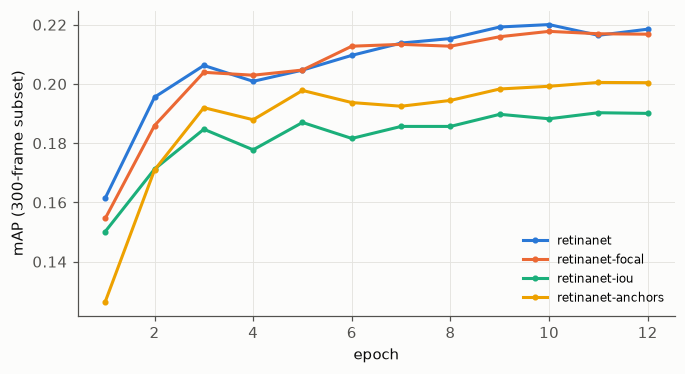

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, name in enumerate(["retinanet", "retinanet-focal", "retinanet-iou", "retinanet-anchors"]):
    path = RUNS / name / "fold0" / "val_curve.csv"
    if path.exists():
        curve = pd.read_csv(path)
        ax.plot(curve["epoch"], curve["mAP"], marker="o", ms=3, color=style.PALETTE[i], label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("mAP (300-frame subset)")
ax.legend(frameon=False, fontsize=8);

## Recall by object size against the tuned two-stage detector
Recall at IoU 0.5 and score 0.3, object side in original-frame pixels.

side,<16,16-32,32-64,64-96,>=96
faster-rcnn-proposals,0.005,0.296,0.547,0.712,0.850
retinanet,0.005,0.258,0.511,0.735,0.897
retinanet-anchors,0.005,0.316,0.569,0.724,0.885


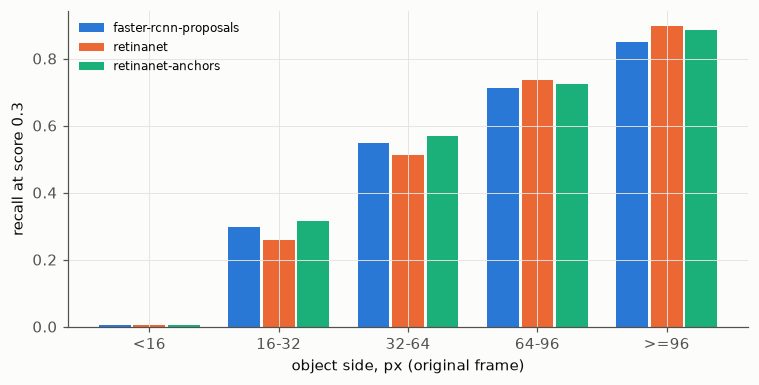

In [5]:
breakdowns = {}
for name in ["faster-rcnn-proposals", "retinanet", "retinanet-anchors"]:
    pred = pd.read_parquet(RUNS / name / "fold0" / "val_predictions.parquet")
    breakdowns[name], _ = results.error_breakdown(tables, pred)
fig = results.plot_size_recall(breakdowns)
pd.DataFrame({k: v["recall"] for k, v in breakdowns.items()}).T

## Errors and failure cases of the best RetinaNet

class confusion    16365
background         15788
localisation       13882
duplicate           1843
Name: count, dtype: int64

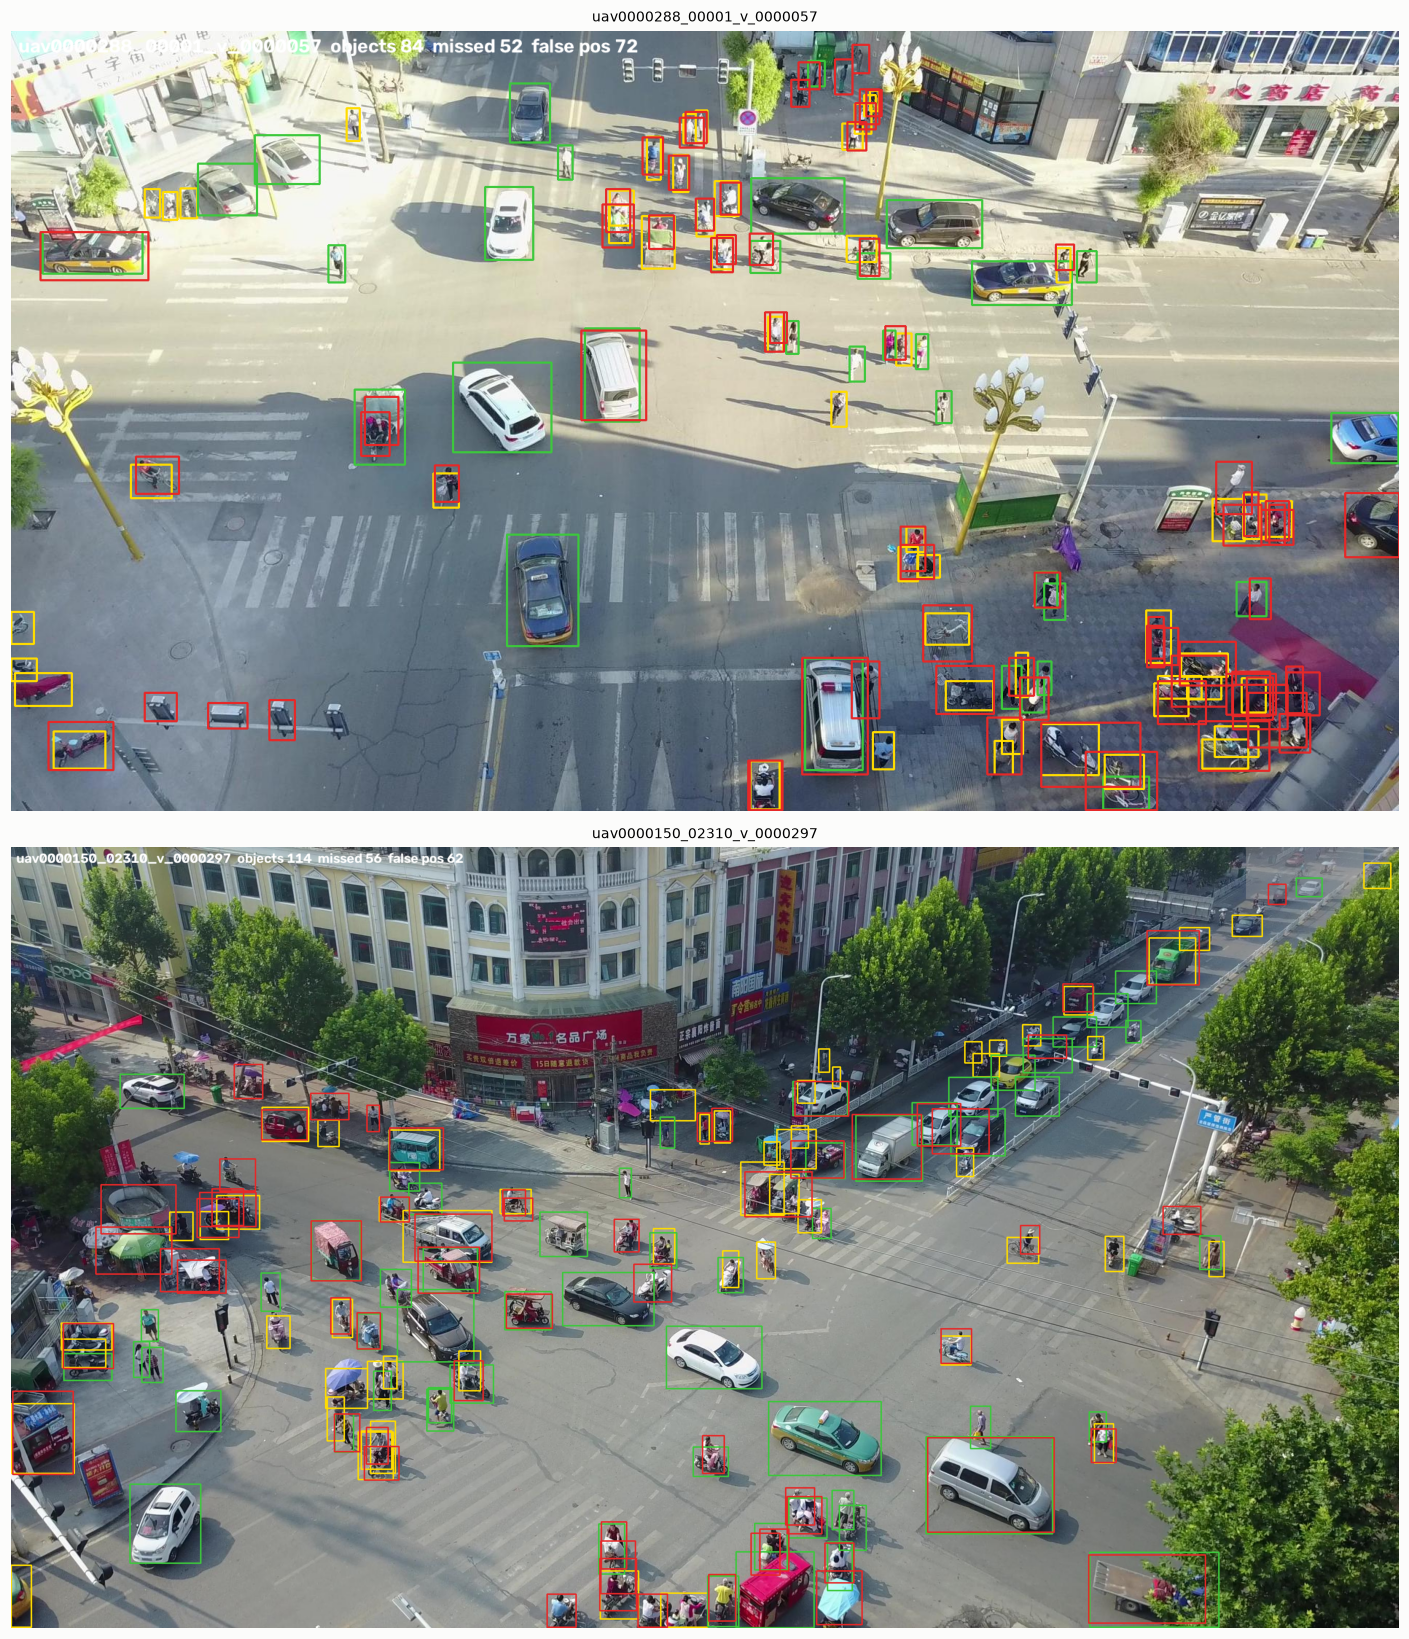

In [6]:
pred = pd.read_parquet(RUNS / "retinanet-focal" / "fold0" / "val_predictions.parquet")
_, fp_kinds = results.error_breakdown(tables, pred)
display(fp_kinds)
worst = results.worst_frames(tables, pred, n=2)
fig, axes = plt.subplots(2, 1, figsize=(13, 15))
for ax, image_id in zip(axes, worst["image_id"], strict=False):
    ax.imshow(gallery.render(tables, pred, image_id, threshold=0.3)[:, :, ::-1])
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")
fig.tight_layout()

## Conclusions
- Without the proposal stage every anchor is classified directly, so the loss is dominated by easy background; the focal loss handles that, and a lower gamma (1.5) helps slightly (+0.004).
- Lowering the IoU thresholds admits low-quality positives and costs 0.022 mAP.
- Anchors fitted to the object sizes (halved) raise AP50 and AP_small but lower mAP: small anchors find more objects but localise them less precisely at high IoU.
- The tuned RetinaNet stays 0.027 below the tuned Faster R-CNN, mostly on small objects: the two-stage RoI refinement matters for 16-32 px objects.